In [784]:
import warnings
warnings.filterwarnings('ignore') 

In [785]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score
import scipy.cluster.hierarchy as sch
import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX

In [786]:
df = pd.read_csv('dublinbike-historical-data-2022-11.csv')

In [787]:
# Display the first five records
df.head()

,STATION ID,TIME,LAST UPDATED,NAME,BIKE_STANDS,AVAILABLE_BIKE_STANDS,AVAILABLE_BIKES,STATUS,ADDRESS,LATITUDE,LONGITUDE
0,1,2022-11-01 00:00:03,2022-10-31 23:51:25,CLARENDON ROW,31,9,22,OPEN,Clarendon Row,53.3409,-6.26250
1,2,2022-11-01 00:00:03,2022-10-31 23:53:48,BLESSINGTON STREET,20,15,5,OPEN,Blessington Street,53.3568,-6.26814
2,3,2022-11-01 00:00:03,2022-10-31 23:50:25,BOLTON STREET,20,17,3,OPEN,Bolton Street,53.3512,-6.26986
3,4,2022-11-01 00:00:03,2022-10-31 23:58:06,GREEK STREET,20,0,20,OPEN,Greek Street,53.3469,-6.27298
4,5,2022-11-01 00:00:03,2022-10-31 23:50:27,CHARLEMONT PLACE,40,31,9,OPEN,Charlemont Street,53.3307,-6.26018


In [788]:
# Display the last five records
df.tail()

,STATION ID,TIME,LAST UPDATED,NAME,BIKE_STANDS,AVAILABLE_BIKE_STANDS,AVAILABLE_BIKES,STATUS,ADDRESS,LATITUDE,LONGITUDE
162602,113,2022-11-30 23:30:02,2022-11-30 23:26:00,MERRION SQUARE SOUTH,40,15,25,OPEN,Merrion Square South,53.3386,-6.24861
162603,114,2022-11-30 23:30:02,2022-11-30 23:26:47,WILTON TERRACE (PARK),40,40,0,OPEN,Wilton Terrace (Park),53.3337,-6.24834
162604,115,2022-11-30 23:30:02,2022-11-30 23:23:32,KILLARNEY STREET,30,5,25,OPEN,Killarney Street,53.3548,-6.24758
162605,116,2022-11-30 23:30:02,2022-11-30 23:25:26,BROADSTONE,30,28,2,OPEN,Broadstone,53.3547,-6.27231
162606,117,2022-11-30 23:30:02,2022-11-30 23:22:24,HANOVER QUAY EAST,40,30,10,OPEN,Hanover Quay East,53.3437,-6.23175


In [789]:
# Number of rows and columns
print("Dataset shape:", df.shape)

Dataset shape: (162607, 11)


In [790]:
# Data type and non nul values of each colun
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 162607 entries, 0 to 162606
Data columns (total 11 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   STATION ID             162607 non-null  int64  
 1   TIME                   162607 non-null  str    
 2   LAST UPDATED           162607 non-null  str    
 3   NAME                   162607 non-null  str    
 4   BIKE_STANDS            162607 non-null  int64  
 5   AVAILABLE_BIKE_STANDS  162607 non-null  int64  
 6   AVAILABLE_BIKES        162607 non-null  int64  
 7   STATUS                 162607 non-null  str    
 8   ADDRESS                162607 non-null  str    
 9   LATITUDE               162607 non-null  float64
 10  LONGITUDE              162607 non-null  float64
dtypes: float64(2), int64(4), str(5)
memory usage: 25.3 MB


In [791]:
# Descriptive statistic of the numerical column
df.describe()

,STATION ID,BIKE_STANDS,AVAILABLE_BIKE_STANDS,AVAILABLE_BIKES,LATITUDE,LONGITUDE
count,162607.000000,162607.000000,162607.000000,162607.000000,162607.000000,162607.000000
mean,58.699115,32.000000,19.783503,11.987965,53.345591,-6.264277
std,34.239989,7.488067,11.218428,9.896961,0.007600,0.017951
min,1.000000,16.000000,0.000000,0.000000,53.330100,-6.310020
25%,29.000000,29.000000,11.000000,3.000000,53.339800,-6.275070
50%,58.000000,30.000000,20.000000,10.000000,53.345200,-6.262980
75%,89.000000,40.000000,29.000000,18.000000,53.350900,-6.251560
max,117.000000,40.000000,40.000000,40.000000,53.360000,-6.230850


In [792]:
# Number of unique value in each column
df.nunique()

STATION ID                  113
TIME                       1439
LAST UPDATED             132190
NAME                        113
BIKE_STANDS                  17
AVAILABLE_BIKE_STANDS        41
AVAILABLE_BIKES              41
STATUS                        1
ADDRESS                     113
LATITUDE                     98
LONGITUDE                   113
dtype: int64

In this dataset there is  162,607 rows and 11 columns. Each row is snapshot of one station at one moment in time: the number of stand BIKE_STANDS), the number of bike available AVAILABLE_BIKES) and the number of free stands AVAILABLE_BIKE_STANDS), together with the station name, address, status and coordinates, there are 113 station and 1,439 diferent read times (about every 30 minutes dure the 30 days of November 2022).

## Step 3: Data cleaning
I check miss values, duplicate, constant or redundant columns and the consistency of the read.

In [793]:
# Check the miss values in each column
df.isnull().sum()

STATION ID               0
TIME                     0
LAST UPDATED             0
NAME                     0
BIKE_STANDS              0
AVAILABLE_BIKE_STANDS    0
AVAILABLE_BIKES          0
STATUS                   0
ADDRESS                  0
LATITUDE                 0
LONGITUDE                0
dtype: int64

In [794]:
# Check the duplicate rows and duplicate station/time readings
print("Duplicated rows:", df.duplicated().sum())
print("Duplicated station/time readings:", df.duplicated(subset = ['STATION ID', 'TIME']).sum())

Duplicated rows: 0
Duplicated station/time readings: 0


In [795]:
# Checking the value of the column status
df['STATUS'].value_counts()

STATUS
OPEN    162607
Name: count, dtype: int64

In [796]:
# Check if the column adress give the same information as the column name
print("Unique names:", df['NAME'].nunique())
print("Unique addresses:", df['ADDRESS'].nunique())

Unique names: 113
Unique addresses: 113


- There are no miss values and no duplicated readings.
- Status have only one value opem), so it is a constant column and give no information to the models.
- Address has the same number of unique values as name (one per station), so it is redundant.
- Last update  is a technical timestamp of the API (when the station last communicated) and is not needed, because we use time as the reading time.
These three columns are removed.

In [797]:
# Drop the constant and redundant columns
df = df.drop(['STATUS', 'ADDRESS', 'LAST UPDATED'], axis = 1)

# Convert the column TIME into datetime format
df['TIME'] = pd.to_datetime(df['TIME'])

# Sort the readings by station and time
df = df.sort_values(['STATION ID', 'TIME']).reset_index(drop = True)

# Display the first five records
df.head()

,STATION ID,TIME,NAME,BIKE_STANDS,AVAILABLE_BIKE_STANDS,AVAILABLE_BIKES,LATITUDE,LONGITUDE
0,1,2022-11-01 00:00:03,CLARENDON ROW,31,9,22,53.3409,-6.2625
1,1,2022-11-01 00:30:02,CLARENDON ROW,31,9,22,53.3409,-6.2625
2,1,2022-11-01 01:00:03,CLARENDON ROW,31,9,22,53.3409,-6.2625
3,1,2022-11-01 01:30:03,CLARENDON ROW,31,9,22,53.3409,-6.2625
4,1,2022-11-01 02:00:04,CLARENDON ROW,31,9,22,53.3409,-6.2625


In [798]:
# Consistency check: bikes + free stand should be equal to the total number of stands
df['STANDS_CHECK'] = df['BIKE_STANDS'] - (df['AVAILABLE_BIKES'] + df['AVAILABLE_BIKE_STANDS'])

# Percentage of readiing where the number do not get a match
print("Readings with a difference:", round((df['STANDS_CHECK'] != 0).mean() * 100, 2), "%")
print(df['STANDS_CHECK'].describe())

Readings with a difference: 6.32 %
count    162607.000000
mean          0.228533
std           2.533585
min           0.000000
25%           0.000000
50%           0.000000
75%           0.000000
max          40.000000
Name: STANDS_CHECK, dtype: float64


In a small share of the readings the sum of bike and free stands is lower than total number of stands, this happen when some stands of bikes are temporary out of service (for example a broken dock). These are a real operational situations, not errors, so the rows are kept, for compare stations of different sizes we will use the occupancy rate (available bikes / total stands) instead absolute numbers.

In [799]:
df = df.drop('STANDS_CHECK', axis = 1)

df['TIME_SLOT'] = df['TIME'].dt.floor('30min')

expected_slots = pd.date_range(start = '2022-11-01 00:00', end = '2022-11-30 23:30', freq = '30min')

missing_slots = expected_slots.difference(df['TIME_SLOT'].unique())
print("Expected slots:", len(expected_slots))
print("Missing slots:", len(missing_slots), list(missing_slots))

Expected slots: 1440
Missing slots: 1 [Timestamp('2022-11-04 23:00:00')]


Only one 30 minute slot is miss (4 November 2022 at 23:00) out of 1,440. This is very small gap, when we build the hourly time serie later, the change in bikes across this gap is stil captured for the next read, so no information about the total demand is lost.

In [800]:
df['OCCUPANCY_RATE'] = df['AVAILABLE_BIKES'] / df['BIKE_STANDS']

df['ACTIVITY'] = df.groupby('STATION ID')['AVAILABLE_BIKES'].diff().abs().fillna(0)

df['HOUR'] = df['TIME'].dt.hour
df['DAY_NAME'] = df['TIME'].dt.day_name()
df['IS_WEEKEND'] = (df['TIME'].dt.dayofweek >= 5).astype(int)

df['PERIOD_OF_DAY'] = pd.cut(df['HOUR'],
                             bins = [-1, 4, 6, 9, 15, 19, 23],
                             labels = ['Overnight', 'Early morning', 'Morning peak', 'Midday', 'Evening peak', 'Night'])

df.head()

,STATION ID,TIME,NAME,BIKE_STANDS,AVAILABLE_BIKE_STANDS,AVAILABLE_BIKES,LATITUDE,LONGITUDE,TIME_SLOT,OCCUPANCY_RATE,ACTIVITY,HOUR,DAY_NAME,IS_WEEKEND,PERIOD_OF_DAY
0,1,2022-11-01 00:00:03,CLARENDON ROW,31,9,22,53.3409,-6.2625,2022-11-01 00:00:00,0.709677,0.0,0,Tuesday,0,Overnight
1,1,2022-11-01 00:30:02,CLARENDON ROW,31,9,22,53.3409,-6.2625,2022-11-01 00:30:00,0.709677,0.0,0,Tuesday,0,Overnight
2,1,2022-11-01 01:00:03,CLARENDON ROW,31,9,22,53.3409,-6.2625,2022-11-01 01:00:00,0.709677,0.0,1,Tuesday,0,Overnight
3,1,2022-11-01 01:30:03,CLARENDON ROW,31,9,22,53.3409,-6.2625,2022-11-01 01:30:00,0.709677,0.0,1,Tuesday,0,Overnight
4,1,2022-11-01 02:00:04,CLARENDON ROW,31,9,22,53.3409,-6.2625,2022-11-01 02:00:00,0.709677,0.0,2,Tuesday,0,Overnight


In [801]:
centre_lat, centre_lon = 53.3473, -6.2591
earth_radius = 6371  # km

lat1, lon1 = np.radians(df['LATITUDE']), np.radians(df['LONGITUDE'])
lat2, lon2 = np.radians(centre_lat), np.radians(centre_lon)

a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
df['DIST_CENTRE_KM'] = 2 * earth_radius * np.arcsin(np.sqrt(a))

df[['NAME', 'DIST_CENTRE_KM']].drop_duplicates().sort_values('DIST_CENTRE_KM').head()

,NAME,DIST_CENTRE_KM
46048,PRINCES STREET / O'CONNELL STREET,0.205387
31658,CUSTOM HOUSE,0.314999
30219,TOWNSEND STREET,0.336254
18707,FOWNES STREET UPPER,0.412891
21585,GEORGES QUAY,0.459218


In [802]:
# Final structure to cleaned the dataset
print("Dataset shape after cleaning:", df.shape)
df.dtypes

Dataset shape after cleaning: (162607, 16)


STATION ID                        int64
TIME                     datetime64[us]
NAME                                str
BIKE_STANDS                       int64
AVAILABLE_BIKE_STANDS             int64
AVAILABLE_BIKES                   int64
LATITUDE                        float64
LONGITUDE                       float64
TIME_SLOT                datetime64[us]
OCCUPANCY_RATE                  float64
ACTIVITY                        float64
HOUR                              int32
DAY_NAME                            str
IS_WEEKEND                        int64
PERIOD_OF_DAY                  category
DIST_CENTRE_KM                  float64
dtype: object

Exploratory data analysis

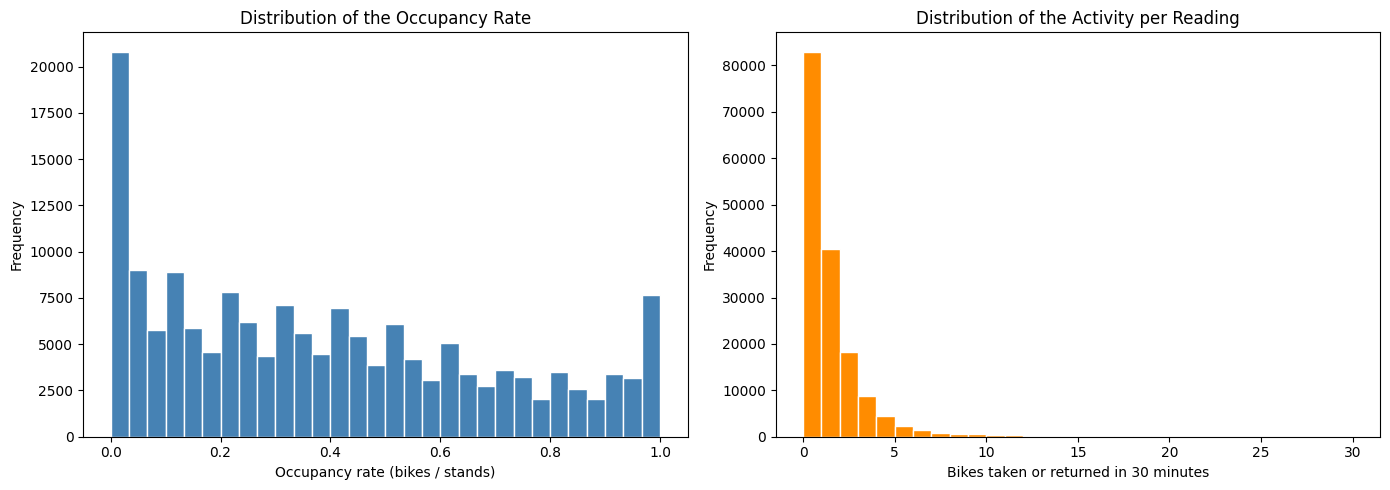

In [803]:
# Distribution of the ocuppancy rate and of the activity
fig, axes = plt.subplots(1, 2, figsize = (14, 5))

axes[0].hist(df['OCCUPANCY_RATE'], bins = 30, color = 'steelblue', edgecolor = 'white')
axes[0].set_title('Distribution of the Occupancy Rate')
axes[0].set_xlabel('Occupancy rate (bikes / stands)')
axes[0].set_ylabel('Frequency')

axes[1].hist(df['ACTIVITY'], bins = 30, color = 'darkorange', edgecolor = 'white')
axes[1].set_title('Distribution of the Activity per Reading')
axes[1].set_xlabel('Bikes taken or returned in 30 minutes')
axes[1].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

- The occupancy rate go from 0 to 1, and many readings are close to 0 (empty station). These are the most difficult situation for users.
- The activity is very right-skewed: in most 30-minute readings there are no change or only a little and only a small number of reading show a lot of movement (busy stations at peak times).

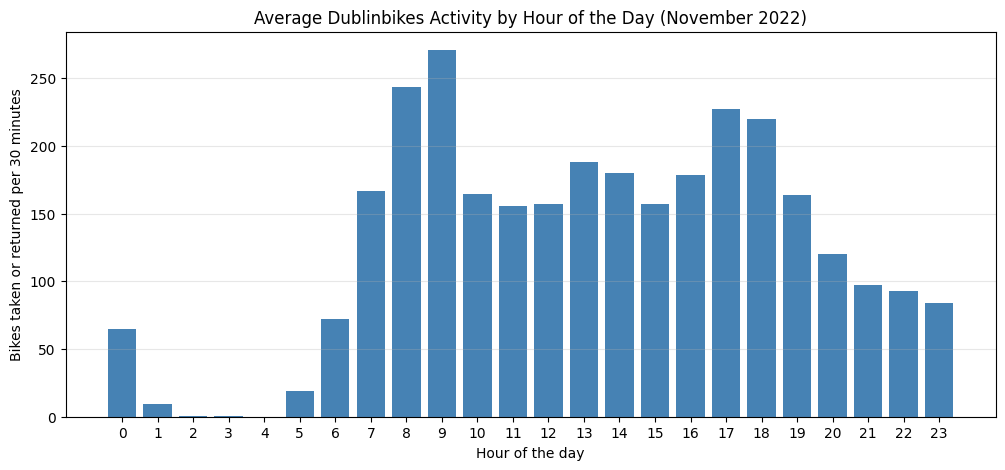

In [804]:
# Total activity in the system in each 30-minute slot then the average for each hour day
hourly_profile = df.groupby(['TIME_SLOT', 'HOUR'])['ACTIVITY'].sum().groupby('HOUR').mean()

plt.figure(figsize = (12, 5))                                              
plt.bar(hourly_profile.index, hourly_profile.values, color = 'steelblue')  
plt.title('Average Dublinbikes Activity by Hour of the Day (November 2022)')
plt.xlabel('Hour of the day')
plt.ylabel('Bikes taken or returned per 30 minutes')
plt.xticks(range(0, 24))                                                   
plt.grid(axis = 'y', alpha = 0.3)                                          
plt.show()

The hourly profile show a clear commuter pattern: a morning peak at 08:00 - 09:00 and during the evening peak at 17:00 - 18:00. Between 01:00 and 04:00 there are almost no activity, because the system is closed at night the customers only can get the bikes from 05:00 to 00:30).

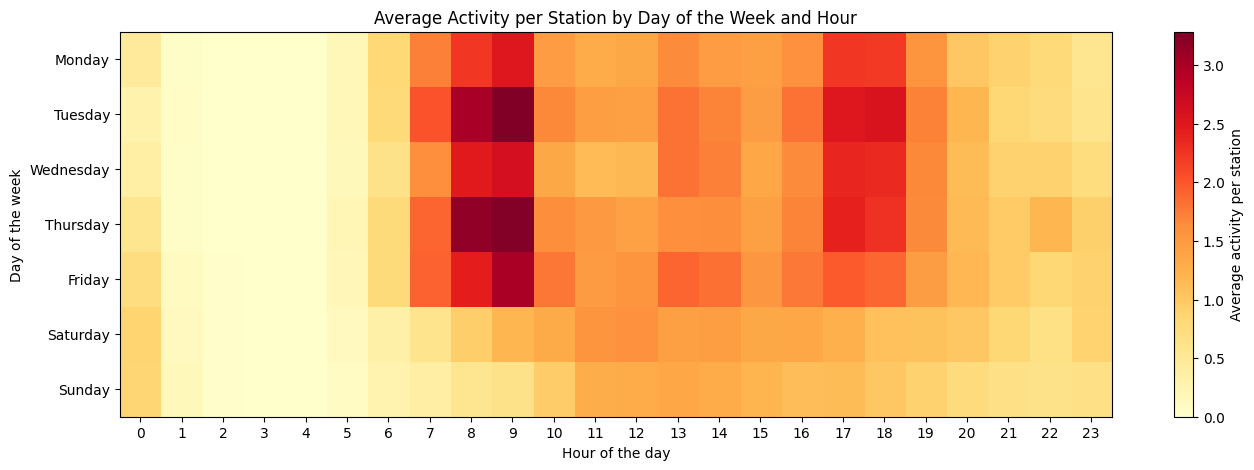

In [805]:
# Order of the days of the week
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

heatmap_data = df.pivot_table(index = 'DAY_NAME', columns = 'HOUR', values = 'ACTIVITY', aggfunc = 'mean').reindex(day_order)

# Plot the heatmap 
plt.figure(figsize = (16, 5))                                         
plt.imshow(heatmap_data.values, cmap = 'YlOrRd', aspect = 'auto')     
plt.colorbar(label = 'Average activity per station')                  
plt.xticks(range(24), heatmap_data.columns)                           
plt.yticks(range(7), heatmap_data.index)                              
plt.title('Average Activity per Station by Day of the Week and Hour')
plt.xlabel('Hour of the day')
plt.ylabel('Day of the week')
plt.show()

The heatmap show the weekdays have two clear peaks (people going to and coming back from work), while Saturdays and Sundays have only one smaler peak in the afternoon (leisure use). It can help to undertand the  difference between weekdays and weekends is important for the clusters and also for the seasonality of the time series.

In [806]:
station_summary = df.groupby(['NAME', 'LATITUDE', 'LONGITUDE']).agg(
    AVG_ACTIVITY = ('ACTIVITY', 'mean'),           
    AVG_OCCUPANCY = ('OCCUPANCY_RATE', 'mean'),    
    BIKE_STANDS = ('BIKE_STANDS', 'first')).reset_index()   

# Top 10 busiest stations
station_summary.sort_values('AVG_ACTIVITY', ascending = False).head(10)

,NAME,LATITUDE,LONGITUDE,AVG_ACTIVITY,AVG_OCCUPANCY,BIKE_STANDS
36,GRAND CANAL DOCK,53.3426,-6.23870,2.258513,0.367981,40
91,PRINCES STREET / O'CONNELL STREET,53.3490,-6.26031,2.240445,0.641206,23
77,MOUNTJOY SQUARE WEST,53.3563,-6.25859,2.235580,0.415404,30
9,CHARLEMONT PLACE,53.3307,-6.26018,2.166088,0.466887,40
96,SIR PATRICK DUN'S,53.3392,-6.24064,2.159138,0.329743,40
26,EXCHEQUER STREET,53.3430,-6.26358,2.029187,0.546242,24
89,PORTOBELLO HARBOUR,53.3304,-6.26516,2.015288,0.486912,30
44,HANOVER QUAY,53.3441,-6.23715,1.822794,0.330629,40
87,PEARSE STREET,53.3443,-6.25043,1.818624,0.373685,30
78,NEW CENTRAL BANK,53.3471,-6.23475,1.813065,0.350956,40


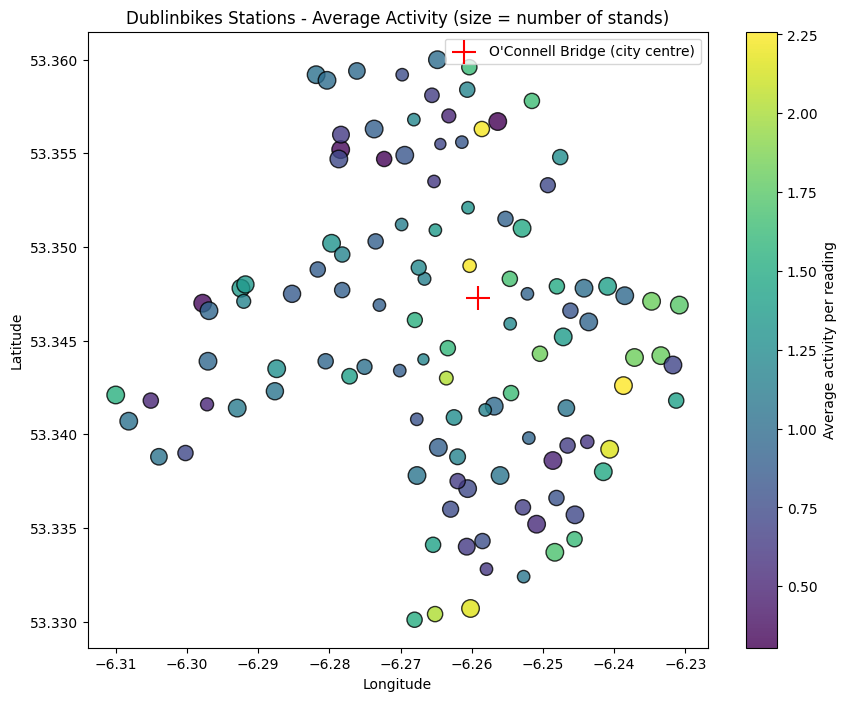

In [807]:
plt.figure(figsize = (10, 8))

plt.scatter(station_summary['LONGITUDE'], station_summary['LATITUDE'],
            c = station_summary['AVG_ACTIVITY'], s = station_summary['BIKE_STANDS'] * 4,
            cmap = 'viridis', alpha = 0.8, edgecolors = 'black')
plt.colorbar(label = 'Average activity per reading')   # Colour scale

plt.scatter(centre_lon, centre_lat, c = 'red', marker = '+', s = 300, label = "O'Connell Bridge (city centre)")

plt.title('Dublinbikes Stations - Average Activity (size = number of stands)')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.legend()
plt.show()

The busiest stations are in the city centre and the Docklands (business area), stations in the west (Kilmainham, Heuston) and in the north of the city there are less activity.

In [808]:
df_service = df[df['HOUR'].between(5, 23)]

# Build one profile for each station, hour and type of day
profiles = df_service.groupby(['STATION ID', 'NAME', 'HOUR', 'IS_WEEKEND']).agg(
    AVG_OCCUPANCY = ('OCCUPANCY_RATE', 'mean'),     
    OCCUPANCY_STD = ('OCCUPANCY_RATE', 'std'),       
    AVG_ACTIVITY = ('ACTIVITY', 'mean'),             
    BIKE_STANDS = ('BIKE_STANDS', 'first'),          
    DIST_CENTRE_KM = ('DIST_CENTRE_KM', 'first'),    
    LATITUDE = ('LATITUDE', 'first'),
    LONGITUDE = ('LONGITUDE', 'first')).reset_index()

# Add the categorical variables for the interpretation
profiles['DAY_TYPE'] = np.where(profiles['IS_WEEKEND'] == 1, 'Weekend', 'Weekday')
profiles['PERIOD_OF_DAY'] = pd.cut(profiles['HOUR'],
                                   bins = [4, 6, 9, 15, 19, 23],
                                   labels = ['Early morning', 'Morning peak', 'Midday', 'Evening peak', 'Night'])

print("Profiles shape:", profiles.shape)
profiles.head()

Profiles shape: (4294, 13)


,STATION ID,NAME,HOUR,IS_WEEKEND,AVG_OCCUPANCY,OCCUPANCY_STD,AVG_ACTIVITY,BIKE_STANDS,DIST_CENTRE_KM,LATITUDE,LONGITUDE,DAY_TYPE,PERIOD_OF_DAY
0,1,CLARENDON ROW,5,0,0.247801,0.276251,0.000000,31,0.746583,53.3409,-6.2625,Weekday,Early morning
1,1,CLARENDON ROW,5,1,0.568548,0.275204,0.000000,31,0.746583,53.3409,-6.2625,Weekend,Early morning
2,1,CLARENDON ROW,6,0,0.260997,0.273968,0.886364,31,0.746583,53.3409,-6.2625,Weekday,Early morning
3,1,CLARENDON ROW,6,1,0.604839,0.261668,0.625000,31,0.746583,53.3409,-6.2625,Weekend,Early morning
4,1,CLARENDON ROW,7,0,0.327713,0.256649,1.409091,31,0.746583,53.3409,-6.2625,Weekday,Morning peak


In [809]:
features = ['AVG_OCCUPANCY', 'OCCUPANCY_STD', 'AVG_ACTIVITY', 'BIKE_STANDS', 'DIST_CENTRE_KM']
profiles[features].describe()

,AVG_OCCUPANCY,OCCUPANCY_STD,AVG_ACTIVITY,BIKE_STANDS,DIST_CENTRE_KM
count,4294.000000,4294.000000,4294.000000,4294.000000,4294.000000
mean,0.383662,0.200883,1.242126,32.000000,1.366219
std,0.223703,0.070031,1.022501,7.488916,0.649399
min,0.004167,0.010078,0.000000,16.000000,0.205387
25%,0.205121,0.154623,0.545455,29.000000,0.935458
50%,0.340767,0.202517,1.062500,30.000000,1.282634
75%,0.540909,0.250009,1.659091,40.000000,1.672485
max,0.993636,0.419076,10.295455,40.000000,3.429335


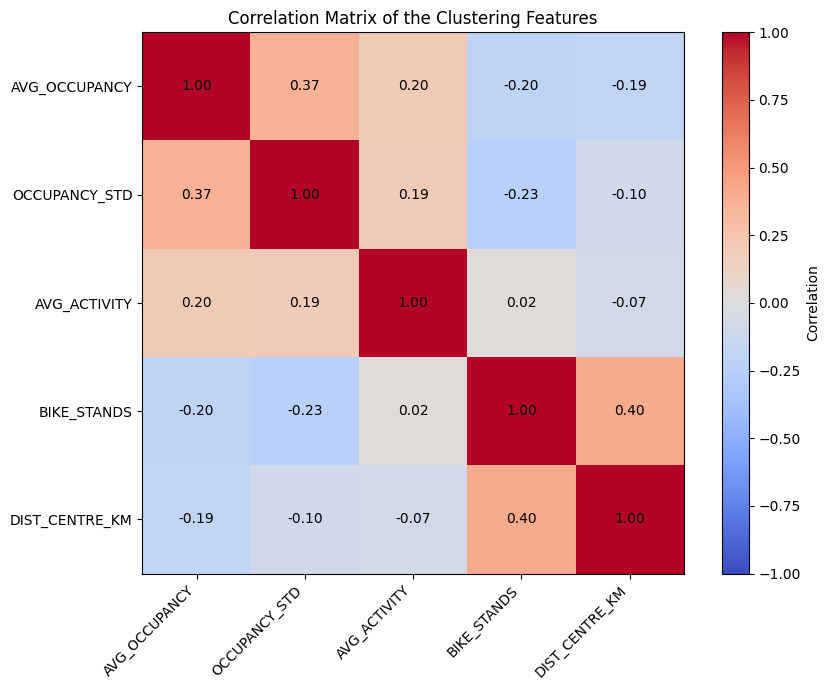

In [810]:
corr_matrix = profiles[features].corr()

plt.figure(figsize = (9, 7))
plt.imshow(corr_matrix, cmap = 'coolwarm', vmin = -1, vmax = 1)
plt.colorbar(label = 'Correlation')

for i in range(len(features)):
    for j in range(len(features)):
        plt.text(j, i, f'{corr_matrix.iloc[i, j]:.2f}', ha = 'center', va = 'center')

plt.xticks(range(len(features)), features, rotation = 45, ha = 'right')
plt.yticks(range(len(features)), features)
plt.title('Correlation Matrix of the Clustering Features')
plt.tight_layout()
plt.show()

The correlation between the features are low or moderate (all lower than 0.4), so each feature gives differents information about the profile. We do not use HOUR, IS_WEEKEND and PERIOD_OF_DAY as inputs, keep them to explain the cluster later (for example, to see if a cluster happen mostly at peak hour).

The features have very different scales (occupancy from 0 to 1, stands from 16 to 40, distance in km). For this reason I standardise them with StandardScaler, so all of them have mean 0 and standard deviation 1 and have the same weight in the distance.

In [811]:
X = profiles[features].values
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(X_scaled[:5])

[[-0.60739703  1.07634491 -1.21493341 -0.13354623 -0.95428002]
 [ 0.8265778   1.06139047 -1.21493341 -0.13354623 -0.95428002]
 [-0.5483992   1.0437403  -0.34797416 -0.13354623 -0.95428002]
 [ 0.98882181  0.8680907  -0.60361599 -0.13354623 -0.95428002]
 [-0.25013244  0.79640393  0.1633095  -0.13354623 -0.95428002]]


# K-Means clustering

The Sum of Squares Error (SSE) is the total squared distance between each point the centroid of it`s cluster, the best number of clusters is at the "elbow" in the graph, where the SSE stops going down a lot.

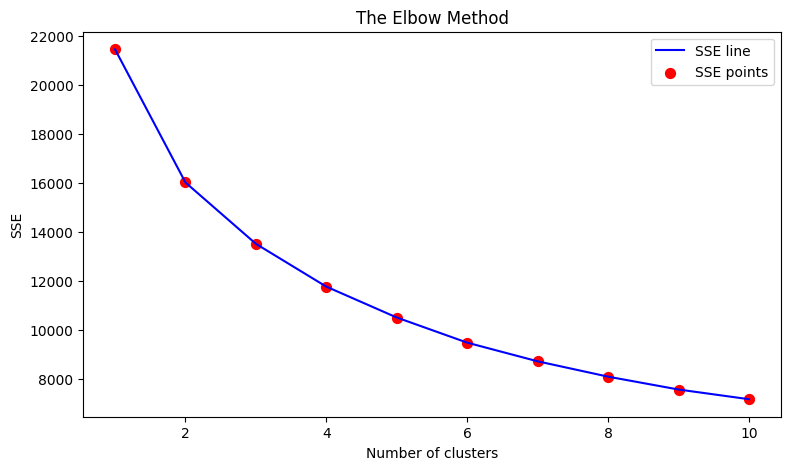

In [812]:
sse = []  

for i in range(1, 11):
    kmeans = KMeans(n_clusters = i, max_iter = 300, n_init = 10, random_state = 42)  # Initialise an object kmeans
    kmeans.fit(X_scaled)                                                             # Training the model
    sse.append(kmeans.inertia_)                                                      # Store kmeans.inertia_ in the array sse

plt.figure(figsize = (9, 5))
plt.plot(range(1, 11), sse, linestyle = '-', color = 'blue', label = 'SSE line')
plt.scatter(range(1, 11), sse, color = 'red', marker = 'o', s = 50, label = 'SSE points')
plt.title('The Elbow Method')
plt.xlabel('Number of clusters')
plt.ylabel('SSE')
plt.legend()
plt.show()

### Silhouette Score and Davies-Bouldin Index to different numbers of clusters

The elbow is not very clear, so compare the Silhouette Score (higher is better) and the Davies-Bouldin Index (lower is better) for k = 2 to 9.

In [813]:
k_values = range(2, 10)    
silhouette_values = []     
dbi_values = []            

for n_clusters in k_values:
    kmeans = KMeans(n_clusters = n_clusters, max_iter = 300, n_init = 10, random_state = 42) 
    labels = kmeans.fit_predict(X_scaled)                           
    silhouette_values.append(silhouette_score(X_scaled, labels))   
    dbi_values.append(davies_bouldin_score(X_scaled, labels))      
    print(f"Silhouette Score (n = {n_clusters}): {silhouette_values[-1]:.4f} | Davies-Bouldin Index (n = {n_clusters}): {dbi_values[-1]:.4f}")

Silhouette Score (n = 2): 0.2438 | Davies-Bouldin Index (n = 2): 1.5865
Silhouette Score (n = 3): 0.2363 | Davies-Bouldin Index (n = 3): 1.5360
Silhouette Score (n = 4): 0.2445 | Davies-Bouldin Index (n = 4): 1.3760
Silhouette Score (n = 5): 0.2161 | Davies-Bouldin Index (n = 5): 1.4236
Silhouette Score (n = 6): 0.2209 | Davies-Bouldin Index (n = 6): 1.3388
Silhouette Score (n = 7): 0.2189 | Davies-Bouldin Index (n = 7): 1.3125
Silhouette Score (n = 8): 0.2078 | Davies-Bouldin Index (n = 8): 1.2671
Silhouette Score (n = 9): 0.2180 | Davies-Bouldin Index (n = 9): 1.2466


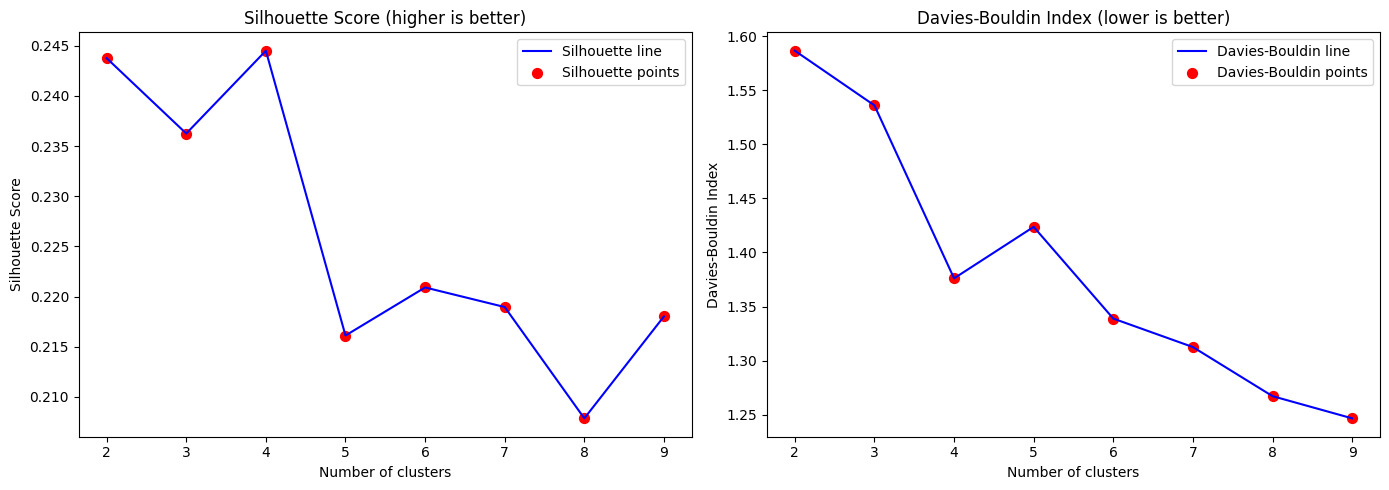

In [814]:
fig, axes = plt.subplots(1, 2, figsize = (14, 5))

axes[0].plot(k_values, silhouette_values, linestyle = '-', color = 'blue', label = 'Silhouette line')
axes[0].scatter(k_values, silhouette_values, color = 'red', marker = 'o', s = 50, label = 'Silhouette points')
axes[0].set_title('Silhouette Score (higher is better)')
axes[0].set_xlabel('Number of clusters')
axes[0].set_ylabel('Silhouette Score')
axes[0].legend()

axes[1].plot(k_values, dbi_values, linestyle = '-', color = 'blue', label = 'Davies-Bouldin line')
axes[1].scatter(k_values, dbi_values, color = 'red', marker = 'o', s = 50, label = 'Davies-Bouldin points')
axes[1].set_title('Davies-Bouldin Index (lower is better)')
axes[1].set_xlabel('Number of clusters')
axes[1].set_ylabel('Davies-Bouldin Index')
axes[1].legend()

plt.tight_layout()
plt.show()